# Using Deep Q-Networks to Solve Cartpole

In [1]:
import gymnasium as gym
import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import random
import copy
from collections import deque


### Offline Data Collection and Training Policy

In [2]:

env = gym.make("CartPole-v1")
obs, info = env.reset(seed=0)   # obs: array of 4 floats

buffer = dict()
counter = 0
n_episodes = 50

#Building out replay buffer with state, action, reward, state', d
for ep in range(n_episodes):
    obs, info = env.reset(seed=ep)   # new episode, new start state
    state = obs
    done = False

    while not done:
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)
        state_prime = obs
        buffer[counter] = [state, action, reward, state_prime, terminated]
        counter += 1

        state = state_prime
        done = terminated or truncated

env.close()
print(counter, "transitions collected")

1260 transitions collected


In [3]:
class QNetwork(nn.Module):
    
    def __init__(self, input_dim, hidden_dim, output_dim = 2):
        super().__init__()
        self.input_layer1 = nn.Linear(in_features= input_dim, out_features= hidden_dim)
        self.input_layer2 = nn.Linear(in_features= hidden_dim, out_features = output_dim)
        self.reset_parameters()
        
    def reset_parameters(self):
        #Standard Xavier init 
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
                    
    def forward(self, x):
        activation1 = nn.functional.relu(self.input_layer1(x))
        activation2 = self.input_layer2(activation1)
        return activation2 
        

### Construction of the loss function 

For $Q_{\theta}$, sample transitions from the replay buffer and compute targets with frozen copy of params $\theta$. Using the formula below, we can then construct an appropriate loss function.

<center> $y = r + \gamma(1-d) \max\limits_{a'} Q_{\theta^-}(s', a')$ </center>

Constructing the loss from this target regression:

<center> $\mathcal{L}(\theta) = \mathbb{E}_{(s,a,r,s'd) \sim \mathcal{D}} [\mathcal{l}(y - Q_{\theta}(s, a))]$  </center>

Where $\mathcal{l}$ is a loss function of choice, let us use MSE in this case.

In [24]:
n_updates = 5000
#Mini batches for calculating loss
batch_size = 64

#Sync target network with frozen network every 500 runs
target_sync_every = 500

#Discount factors 
gamma = 0.99
LEARNING_RATE = 3e-4
#Lets try a sample update for one point

#Define Q Network 
network = QNetwork(input_dim = 4, hidden_dim = 64, output_dim= 2)

#MSE loss and Adam
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(network.parameters(), lr = LEARNING_RATE)

#Frozen network weights for y
target_net = copy.deepcopy(network)          
for p in target_net.parameters():
    p.requires_grad_(False)  

keys = list(buffer.keys())
running = []

#Passing in as dictionary so it looks cleaner 
params = {
    "network": network,
    "target": target_net,
    "optimizer": torch.optim.Adam(network.parameters(), lr=3e-4), 
    "loss": nn.MSELoss(),
    "gamma": 0.99,
    "batch_size": 64,
    "sync": 500,
}

#This is used rn for offline training, but is also going to be used for the online loop
def train_step(params, buffer):
    #One DQN gradient step, buffer: list or deque of (s, a, r, s', d)
    net, tgt, opt = params["network"], params["target"], params["optimizer"]

    #Experience replay step
    batch = random.sample(buffer, params["batch_size"])
    states, actions, rewards, next_states, terms = zip(*batch)

    states      = torch.tensor(np.array(states), dtype=torch.float32)
    actions     = torch.tensor(actions, dtype=torch.int64)
    rewards     = torch.tensor(rewards, dtype=torch.float32)
    next_states = torch.tensor(np.array(next_states), dtype=torch.float32)
    d           = torch.tensor(terms, dtype=torch.float32)
    #Q-value for state action
    q_sa = net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
        max_next = tgt(next_states).max(dim=1).values
        y = rewards + params["gamma"] * (1 - d) * max_next

    loss = params["loss"](q_sa, y)
    opt.zero_grad()
    loss.backward()
    opt.step()

    return loss.item(), q_sa.mean().item()


def sync_target(params):
    params["target"].load_state_dict(params["network"].state_dict())


def train_offline(params, buffer, n_updates):
    running = []
    for step in range(n_updates):
        loss, mean_q = train_step(params, buffer)
        running.append(loss)
        if (step + 1) % params["sync"] == 0:
            sync_target(params)
            print(f"step {step + 1:5d}  avg loss {np.mean(running):.4f}  mean Q {mean_q:.2f}")
            running = []

### $\varepsilon$-Greedy Policy

For any action, with probability $\varepsilon$, we will use a random action, with the remaining probability being allocated to using the highest Q-value at time $\mathcal{t}$.

In [5]:
def epsilon_greedy(epsilon, network, state):
    num = random.uniform(0, 1)
    #left or right, env.action_space -> Discrete(2), so hardcoding actions for this problem
    actions = [0, 1]
    if(num < epsilon):
        return random.choice(actions)
    else:
        with torch.no_grad():
            x = torch.tensor(state, dtype = torch.float32)
            return network(x).argmax().item()

### Online Policy and Deployment

In [29]:
#Building out replay buffer with state, action, reward, state', d
#New params dict because going to start from scratch without rollout
n_episodes = 2000
q_net = QNetwork(input_dim = 4, hidden_dim = 64, output_dim= 2)
tgt_net = copy.deepcopy(q_net)          
for p in tgt_net.parameters():
    p.requires_grad_(False)  


params_online = {
    "network": q_net,
    "target": tgt_net,
    "optimizer": torch.optim.Adam(q_net.parameters(), lr=3e-4), 
    "loss": nn.MSELoss(),
    "gamma": 0.99,
    "batch_size": 64,
    "sync": 500,
}

#deque object for experience replay
replay = deque(maxlen = 50000)
episodes_return = []
recent_returns = deque(maxlen = 20)
global_steps = 0

for ep in range(n_episodes):
    print(ep)
    obs, info = env.reset(seed=ep)   # new episode, new start state
    state = obs
    done = False
    ep_return = 0.0
    #Decay based off episode, less exploration with a better target policy as time goes on, setting cap at 0.05 due to catastrophic forgetting, bad transitions get pushed out of deque, so this mitigates large dips in performance
    epsilon = max(0.05 , 1 - ep/n_episodes)
    while not done:
        action = epsilon_greedy(epsilon, q_net, obs)
        obs, reward, terminated, truncated, info = env.step(action)
        global_steps += 1
        ep_return += reward
        state_prime = obs
        replay.append((state, action, reward, state_prime, terminated))
        if(len(replay) >= 1000):
            loss_q, mean_q = train_step(params_online, replay)
        if(global_steps % params_online["sync"] == 0):
            sync_target(params_online)

        state = state_prime
        done = terminated or truncated
        if(len(replay) > 1000 and len(replay) % 500 == 0):
            continue
            #print(loss_q, mean_q, np.mean(recent_returns))
    episodes_return.append(ep_return)
    recent_returns.append(ep_return)
env.close()
print(f"Finished: {ep} episodes, {global_steps} steps")

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

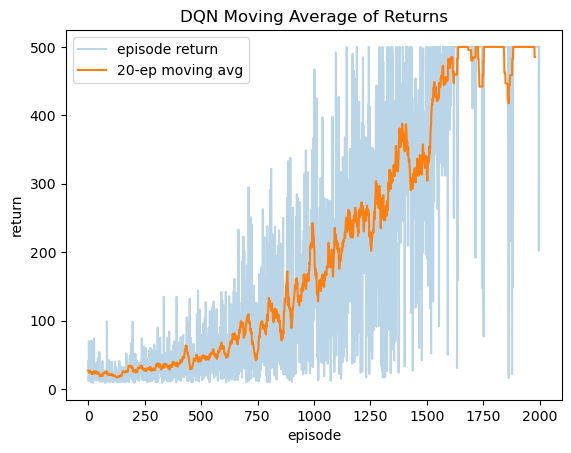

In [30]:
plt.plot(episodes_return, alpha=0.3, label="episode return")
plt.plot(np.convolve(episodes_return, np.ones(20) / 20, mode="valid"), label="20-ep moving avg")
plt.xlabel("episode")
plt.ylabel("return")
plt.title("DQN Moving Average of Returns")
plt.legend()
plt.show()

# Rendering the Environment

In [28]:
from matplotlib import animation
from IPython.display import HTML
import torch

# Separate env just for viewing (the training env can't render)
view_env = gym.make("CartPole-v1", render_mode="rgb_array")

def greedy_policy(obs):
    with torch.no_grad():
        q = q_net(torch.tensor(obs, dtype=torch.float32))
        return q.argmax().item()

def record_episode(env, policy, seed=0):
    obs, info = env.reset(seed=seed)
    frames, total = [env.render()], 0.0
    terminated = truncated = False
    while not (terminated or truncated):
        #Strictly make decisions based off of Q-network, equivalent to epsilon = 0.
        obs, reward, terminated, truncated, info = env.step(policy(obs))
        total += reward
        frames.append(env.render())
    return frames, total

def play(frames, fps=50):
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.axis("off")
    img = ax.imshow(frames[0])
    anim = animation.FuncAnimation(fig, lambda i: img.set_data(frames[i]),
                                   frames=len(frames), interval=1000 / fps)
    plt.close(fig)
    return HTML(anim.to_jshtml())

frames, total = record_episode(view_env, greedy_policy, seed=123)
print(f"Return: {total:.0f}")
play(frames)

Return: 500


## Trying out Double Deep Q-Networks

### Double DQN

DDQN reduces the overestimation bias in the DQN regression target. Recall:

$$y = r + \gamma(1-d) \max_{a'} Q_{\theta^-}(s', a')$$

Model each estimate as the true value plus zero-mean noise, $Q_{\theta^-}(s',a') = Q^{\text{true}}(s',a') + \varepsilon_{a'}$ with $\mathbb{E}[\varepsilon_{a'}] = 0$. Given $r, d$ and, $y$ are affine in the max:

<center> $\mathbb{E}[y] = r + \gamma(1-d)\,\mathbb{E}\Big[\max_{a'} Q_{\theta^-}(s', a')\Big]$ </center>

Since the max function is convex, Jensen's inequality gives:

<center> $\mathbb{E}\Big[\max_{a'} Q_{\theta^-}(s', a')\Big] \;\ge\; \max_{a'} \mathbb{E}\big[Q_{\theta^-}(s', a')\big] = \max_{a'} Q^{true}(s', a').$ </center>

So even though each estimate is unbiased, the target $y$ is biased upward: the max preferentially selects whichever action received positive noise. The network is trained toward this inflated target, and through bootstrapping the bias propagates to earlier states and compounds.

The fix: Decouple the selection from evaluation. The online network selects the action, and the target network evaluates it:

$$a^* = \arg\max_{a'} Q_{\theta}(s', a'), \qquad y = r + \gamma(1-d)\, Q_{\theta^-}(s', a^*).$$

Since the target network's error at $a^*$ is (approximately) independent of the noise that caused $a^*$ to be selected, it averages to roughly zero, so the lucky boost from the max is largely removed. The two networks' errors are still correlated, since $\theta^-$ is a lagged copy of $\theta$, so the bias is reduced.

In [33]:
n_updates = 5000
#Mini batches for calculating loss
batch_size = 64

#Sync target network with frozen network every 500 runs
target_sync_every = 500

#Discount factors 
gamma = 0.99
LEARNING_RATE = 3e-4
#Lets try a sample update for one point

#Define Q Network 
network = QNetwork(input_dim = 4, hidden_dim = 64, output_dim= 2)

#MSE loss and Adam
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(network.parameters(), lr = LEARNING_RATE)

#Frozen network weights for y
target_net = copy.deepcopy(network)          
for p in target_net.parameters():
    p.requires_grad_(False)  

keys = list(buffer.keys())
running = []

#Passing in as dictionary so it looks cleaner 
params = {
    "network": network,
    "target": target_net,
    "optimizer": torch.optim.Adam(network.parameters(), lr=3e-4), 
    "loss": nn.MSELoss(),
    "gamma": 0.99,
    "batch_size": 64,
    "sync": 500,
}

#This is used rn for offline training, but is also going to be used for the online loop
def ddqn_train_step(params, buffer):
    #One DQN gradient step, buffer: list or deque of (s, a, r, s', d)
    net, tgt, opt = params["network"], params["target"], params["optimizer"]

    #Experience replay step
    batch = random.sample(buffer, params["batch_size"])
    states, actions, rewards, next_states, terms = zip(*batch)

    states      = torch.tensor(np.array(states), dtype=torch.float32)
    actions     = torch.tensor(actions, dtype=torch.int64)
    rewards     = torch.tensor(rewards, dtype=torch.float32)
    next_states = torch.tensor(np.array(next_states), dtype=torch.float32)
    d           = torch.tensor(terms, dtype=torch.float32)
    #Q-value for state action
    q_sa = net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
        #Implementing DDQN, using bias-reduction technique to get output from network and match index to target network 
        best_a   = net(next_states).argmax(dim=1, keepdim=True) 
        max_next = tgt(next_states).gather(1, best_a).squeeze(1)
        y = rewards + params["gamma"] * (1 - d) * max_next

    loss = params["loss"](q_sa, y)
    opt.zero_grad()
    loss.backward()
    opt.step()

    return loss.item(), q_sa.mean().item()


def sync_target(params):
    params["target"].load_state_dict(params["network"].state_dict())


def train_offline(params, buffer, n_updates):
    running = []
    for step in range(n_updates):
        loss, mean_q = train_step(params, buffer)
        running.append(loss)
        if (step + 1) % params["sync"] == 0:
            sync_target(params)
            print(f"step {step + 1:5d}  avg loss {np.mean(running):.4f}  mean Q {mean_q:.2f}")
            running = []

In [40]:
#Building out replay buffer with state, action, reward, state', d
#New params dict because going to start from scratch without rollout
total_return_frame =[]
for i in range(6):
    print(i)
    n_episodes = 2000
    q_net = QNetwork(input_dim = 4, hidden_dim = 64, output_dim= 2)
    tgt_net = copy.deepcopy(q_net)          
    for p in tgt_net.parameters():
        p.requires_grad_(False)  
    
    
    params_online = {
        "network": q_net,
        "target": tgt_net,
        "optimizer": torch.optim.Adam(q_net.parameters(), lr=3e-4), 
        "loss": nn.MSELoss(),
        "gamma": 0.99,
        "batch_size": 64,
        "sync": 500,
    }
    
    #deque object for experience replay
    replay = deque(maxlen = 50000)
    episodes_return = []
    recent_returns = deque(maxlen = 20)
    global_steps = 0
    
    for ep in range(n_episodes):
        obs, info = env.reset(seed=ep)   # new episode, new start state
        state = obs
        done = False
        ep_return = 0.0
        #Decay based off episode, less exploration with a better target policy as time goes on
        epsilon = max(0.05, 1 - ep/n_episodes)
        while not done:
            action = epsilon_greedy(epsilon, q_net, obs)
            obs, reward, terminated, truncated, info = env.step(action)
            global_steps += 1
            ep += 1 ## Increment to change the seed to get actions from environment
            ep_return += reward
            state_prime = obs
            replay.append((state, action, reward, state_prime, terminated))
            if(len(replay) >= 1000):
                loss_q, mean_q = ddqn_train_step(params_online, replay)
            if(global_steps % params_online["sync"] == 0):
                sync_target(params_online)
    
            state = state_prime
            done = terminated or truncated
            if(len(replay) > 1000 and len(replay) % 500 == 0):
                continue
                #print(loss_q, mean_q, np.mean(recent_returns))
        episodes_return.append(ep_return)
        recent_returns.append(ep_return)
    total_return_frame.append(episodes_return)
    env.close()
    print(f"Finished: {ep} episodes, {global_steps} steps")


0
Finished: 2499 episodes, 397779 steps
1
Finished: 2499 episodes, 396576 steps
2
Finished: 2499 episodes, 422245 steps
3
Finished: 2499 episodes, 450554 steps
4
Finished: 2499 episodes, 434452 steps
5
Finished: 2499 episodes, 422588 steps


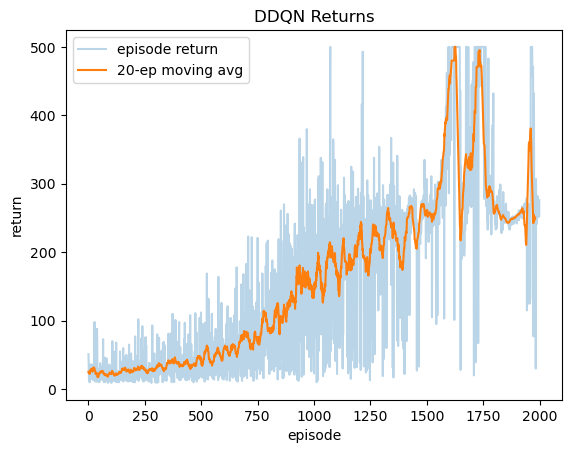

In [38]:
plt.plot(episodes_return, alpha=0.3, label="episode return")
plt.plot(np.convolve(episodes_return, np.ones(20) / 20, mode="valid"), label="20-ep moving avg")
plt.xlabel("episode")
plt.ylabel("return")
plt.legend()
plt.title("DDQN Returns")
plt.show()

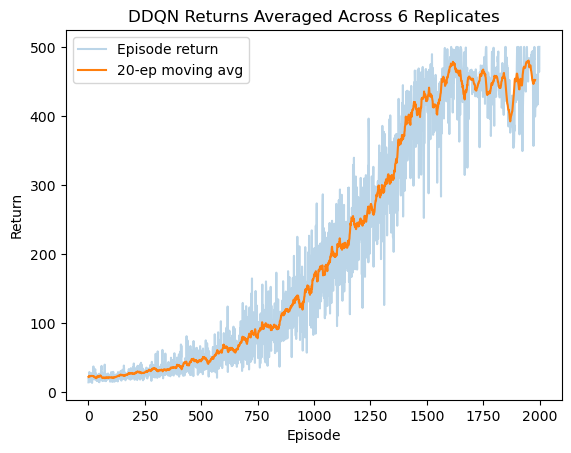

In [47]:
avg_returns = np.mean(total_return_frame, axis = 0)
plt.plot(avg_returns, alpha=0.3, label="Episode return")
plt.plot(np.convolve(avg_returns, np.ones(20) / 20, mode="valid"), label="20-ep moving avg")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.legend()
plt.title("DDQN Returns Averaged Across 6 Replicates")
plt.show()